<a href="https://colab.research.google.com/github/likithdr06/DLNN-lab-exp/blob/main/Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Generate sample time-series data

time = np.arange(1000)

data = (
    np.sin(time * 0.02)
    + 0.5 * np.sin(time * 0.05)
    + np.random.normal(0, 0.1, 1000)
)

# Create DataFrame
df = pd.DataFrame({
    'Day': time,
    'Value': data
})

print(df.head())
print("\nDataset Shape:", df.shape)

   Day     Value
0    0  0.049671
1    1  0.031162
2    2  0.154675
3    3  0.286986
4    4  0.155834

Dataset Shape: (1000, 2)


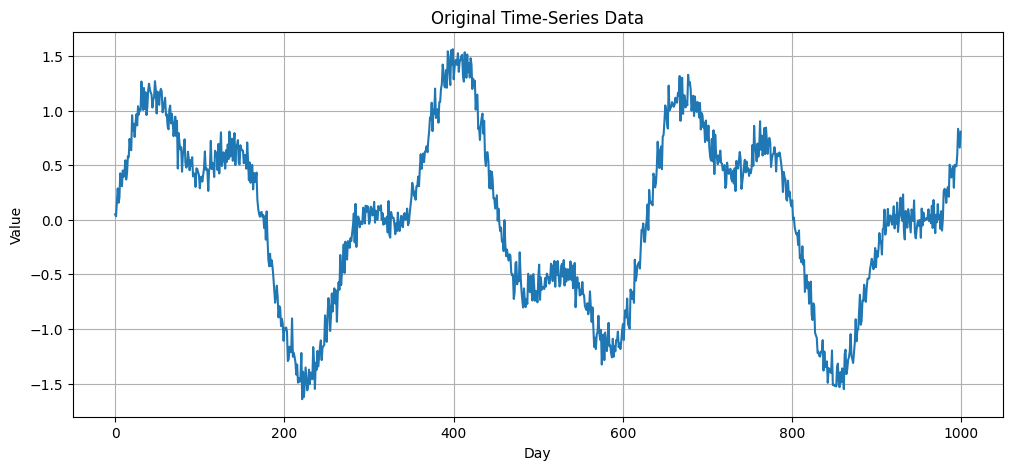

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df['Day'], df['Value'])

plt.title("Original Time-Series Data")
plt.xlabel("Day")
plt.ylabel("Value")

plt.grid()
plt.show()

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(
    df[['Value']]
)

print("Data Normalized Successfully!")

print(scaled_data[:5])


Data Normalized Successfully!
[[0.52828786]
 [0.52251281]
 [0.56104923]
 [0.60233067]
 [0.56141088]]


In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(
    df[['Value']]
)

print("Data Normalized Successfully!")

print(scaled_data[:5])

Data Normalized Successfully!
[[0.52828786]
 [0.52251281]
 [0.56104923]
 [0.60233067]
 [0.56141088]]


In [ ]:
def create_sequences(dataset, window_size=20):

    X = []
    y = []

    for i in range(len(dataset) - window_size):

        X.append(dataset[i:i + window_size])

        y.append(dataset[i + window_size])

    return np.array(X), np.array(y)


X, y = create_sequences(scaled_data, 20)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (980, 20, 1)
Output Shape: (980, 1)


In [ ]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (784, 20, 1)
Testing Data: (196, 20, 1)


In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Early Stopping Configured!")

Early Stopping Configured!


In [ ]:
rnn_model = Sequential([

    Input(shape=(20, 1)),

    SimpleRNN(
        64,
        activation='tanh'
    ),

    Dense(32, activation='relu'),

    Dense(1)

])

rnn_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("SimpleRNN Training Completed!")

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.0702 - mae: 0.1547 - val_loss: 0.0135 - val_mae: 0.1095
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0036 - mae: 0.0489 - val_loss: 0.0024 - val_mae: 0.0395
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0019 - mae: 0.0346 - val_loss: 0.0016 - val_mae: 0.0312
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0017 - mae: 0.0330 - val_loss: 0.0014 - val_mae: 0.0298
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0017 - mae: 0.0333 - val_loss: 0.0014 - val_mae: 0.0299
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0017 - mae: 0.0332 - val_loss: 0.0014 - val_mae: 0.0296
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0017 - mae: 0.0333 - val_loss: 0.0014 - val_mae: 0.0293
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0017 - mae: 0.0333 - val_loss: 0.0014 - val_mae: 0.0297
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.001

In [ ]:
gru_model = Sequential([

    Input(shape=(20, 1)),

    GRU(
        64,
        activation='tanh'
    ),

    Dense(32, activation='relu'),

    Dense(1)

])

gru_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("GRU Training Completed!")

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - loss: 0.0911 - mae: 0.2270 - val_loss: 0.0078 - val_mae: 0.0795
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0081 - mae: 0.0738 - val_loss: 0.0027 - val_mae: 0.0434
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0035 - mae: 0.0482 - val_loss: 0.0022 - val_mae: 0.0386
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0019 - mae: 0.0350 - val_loss: 0.0016 - val_mae: 0.0322
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0016 - mae: 0.0316 - val_loss: 0.0014 - val_mae: 0.0284
GRU Training Completed!


In [ ]:
rnn_loss, rnn_mae = rnn_model.evaluate(
    X_test, y_test, verbose=0
)

gru_loss, gru_mae = gru_model.evaluate(
    X_test, y_test, verbose=0
)

print("SimpleRNN Performance")
print("MSE Loss:", rnn_loss)
print("MAE:", rnn_mae)

print("\nGRU Performance")
print("MSE Loss:", gru_loss)
print("MAE:", gru_mae)

SimpleRNN Performance
MSE Loss: 0.001448054681532085
MAE: 0.03005686029791832

GRU Performance
MSE Loss: 0.02079007774591446
MAE: 0.13438989222049713


In [ ]:
rnn_predictions = rnn_model.predict(X_test)

gru_predictions = gru_model.predict(X_test)

print("Predictions Generated Successfully!")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step
Predictions Generated Successfully!


In [ ]:
rnn_predictions = scaler.inverse_transform(
    rnn_predictions
)

gru_predictions = scaler.inverse_transform(
    gru_predictions
)

actual_values = scaler.inverse_transform(
    y_test
)

print("Predictions Converted Successfully!")

Predictions Converted Successfully!


In [ ]:
rnn_mse = mean_squared_error(
    actual_values, rnn_predictions
)

gru_mse = mean_squared_error(
    actual_values, gru_predictions
)

rnn_mae_original = mean_absolute_error(
    actual_values, rnn_predictions
)

gru_mae_original = mean_absolute_error(
    actual_values, gru_predictions
)

print("SimpleRNN MSE:", rnn_mse)
print("GRU MSE:", gru_mse)

print("\nSimpleRNN MAE:", rnn_mae_original)
print("GRU MAE:", gru_mae_original)

SimpleRNN MSE: 0.014875384813049494
GRU MSE: 0.21356958270913975

SimpleRNN MAE: 0.09633525791213463
GRU MAE: 0.4307331310121792


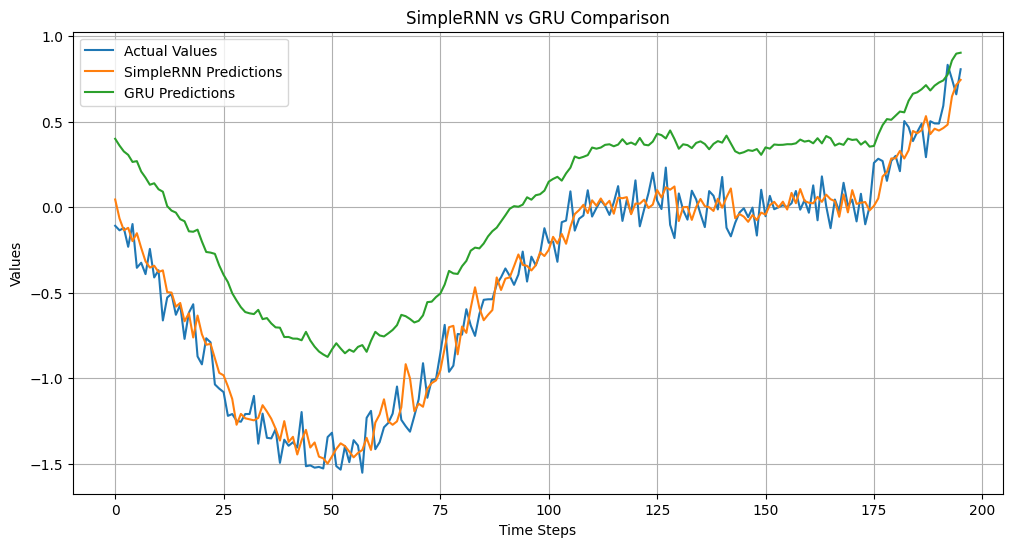

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    actual_values,
    label="Actual Values"
)

plt.plot(
    rnn_predictions,
    label="SimpleRNN Predictions"
)

plt.plot(
    gru_predictions,
    label="GRU Predictions"
)

plt.title("SimpleRNN vs GRU Comparison")

plt.xlabel("Time Steps")
plt.ylabel("Values")

plt.legend()
plt.grid()

plt.show()